# Gemma-3-1B-IT (decoder-only): zero-shot prompting and LoRA fine-tuning, English to Hindi

Gemma 3 1B IT (Google DeepMind, 2025) is a decoder-only model with 26 layers, a mix of local and global
attention, and RoPE. Its 262k SentencePiece vocabulary was built for 140+ languages. It was pretrained on 2T tokens
and then instruction tuned.

I try two ways of using it, both on the same test set:
1. Zero-shot prompting. The chat model gets the instruction "Translate the following English sentence into Hindi.
   Reply with only the Hindi translation." No training at all.
2. LoRA fine-tuning. Low-rank adapters (r=16, alpha=32, dropout 0.05) on all attention and MLP projections, trained
   for 1 epoch on 10,000 pairs from the shared training set. Each example is the same chat prompt with the Hindi
   reference as the reply, and the loss is only on the reply tokens. AdamW lr 2e-4, cosine schedule, batch 4 with
   4 gradient accumulation steps.

The model is kept in fp32. The T4 has no bf16, and Gemma 3 overflows in fp16, so I used fp32 for both LLMs to keep
the comparison fair. The weights are loaded from `unsloth/gemma-3-1b-it`, an ungated copy of `google/gemma-3-1b-it`, so no Hugging Face token is needed.

I ran this on Kaggle (Tesla T4). The outputs shown below are from that run; the full log is in `results/logs/`.

In [1]:
!pip -q install sacrebleu peft
!pip -q uninstall -y torchao   # Kaggle's old torchao (0.10) makes peft refuse to load; LoRA does not need it

In [2]:
import os, json, time, random, re
import numpy as np, pandas as pd, torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
SMOKE = os.environ.get("SMOKE") == "1"   # tiny CPU run used only to test the code
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATA_URL = os.environ.get("DATA_URL", "https://raw.githubusercontent.com/UtkarshKumarJha/GenAI-IA3/main/data/")
load = lambda name: pd.read_json(DATA_URL + name, lines=True)
train, valid, test, probes = (load(f) for f in ("train.jsonl", "valid.jsonl", "test.jsonl", "probes.jsonl"))
temp_set = test.iloc[:200]          # subset used for the sampling-temperature study
TEMPS = [0.5, 1.0, 1.5]             # main results use greedy decoding (T -> 0)
if SMOKE:
    train, valid, test, temp_set, probes = train[:200], valid[:16], test[:8], test[:4], probes[:4]
print(f"train {len(train):,} | valid {len(valid)} | test {len(test)} | probes {len(probes)} | device {DEVICE}",
      torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

train 100,000 | valid 520 | test 1000 | probes 44 | device cuda Tesla T4


In [3]:
def save_jsonl(df, path):
    df.to_json(path, orient="records", lines=True, force_ascii=False)

def run_all(translate, tag, out):
    """Greedy test translations (timed), temperature samples, and probe translations -> out/"""
    os.makedirs(out, exist_ok=True)
    t0 = time.perf_counter()
    hyps = translate(test.en.tolist())
    infer_s = time.perf_counter() - t0
    save_jsonl(test.assign(hyp=hyps), f"{out}/test_preds.jsonl")
    import sacrebleu
    bleu = sacrebleu.corpus_bleu(hyps, [test.hi.tolist()], tokenize="intl").score
    chrf = sacrebleu.corpus_chrf(hyps, [test.hi.tolist()]).score
    print(f"[{tag}] BLEU {bleu:.2f} | chrF {chrf:.2f} | {infer_s:.1f}s for {len(test)} sentences")
    for en, ref, hyp in list(zip(test.en, test.hi, hyps))[:3]:
        print(f"  EN : {en}\n  REF: {ref}\n  HYP: {hyp}\n")
    save_jsonl(probes.assign(hyp=translate(probes.en.tolist())), f"{out}/probe_preds.jsonl")
    return dict(infer_time_s=infer_s, infer_sent_per_s=len(test) / infer_s, quick_bleu=bleu, quick_chrf=chrf)

def run_temperatures(translate_sampled, out):
    rows = []
    for T in TEMPS:
        torch.manual_seed(SEED)
        for en, ref, hyp in zip(temp_set.en, temp_set.hi, translate_sampled(temp_set.en.tolist(), T)):
            rows.append(dict(temperature=T, en=en, hi=ref, hyp=hyp))
    save_jsonl(pd.DataFrame(rows), f"{out}/temperature_preds.jsonl")

In [4]:
import transformers, peft
from transformers import AutoTokenizer, AutoModelForCausalLM, get_cosine_schedule_with_warmup
from peft import LoraConfig, get_peft_model
print("transformers", transformers.__version__, "| peft", peft.__version__)
transformers.logging.set_verbosity_error()   # silence per-batch generation warnings

KEY, MODEL_ID = "gemma", "unsloth/gemma-3-1b-it"
CFG = dict(n_train=10_000, batch=4, accum=4, lr=2e-4, warmup=30, max_len=256,
           lora_r=16, lora_alpha=32, lora_dropout=0.05, gen_bs=16, max_new=256)
if SMOKE: CFG.update(n_train=8, batch=2, accum=2, warmup=1, gen_bs=4, max_new=24)

tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"                      # left padding for batched generation
if tok.pad_token is None: tok.pad_token = tok.eos_token
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, attn_implementation="eager").float().to(DEVICE)
model.generation_config.pad_token_id = tok.pad_token_id
n_params = model.num_parameters()
print(f"parameters: {n_params / 1e6:.1f} M")

INSTRUCTION = "Translate the following English sentence into Hindi. Reply with only the Hindi translation.\n\nEnglish: "
def prompt(en):
    return tok.apply_chat_template([dict(role="user", content=INSTRUCTION + en)], tokenize=False, add_generation_prompt=True)
print(prompt(test.en[0]))
print(tok.tokenize(test.en[0])[:25]); print(tok.tokenize(test.hi[0])[:25])

transformers 5.16.1 | peft 0.20.0
parameters: 999.9 M
<bos><start_of_turn>user
Translate the following English sentence into Hindi. Reply with only the Hindi translation.

English: Due to financial constraints Dhirubhai had to drop out after high school.<end_of_turn>
<start_of_turn>model

['Due', '▁to', '▁financial', '▁constraints', '▁Dh', 'ir', 'ub', 'hai', '▁had', '▁to', '▁drop', '▁out', '▁after', '▁high', '▁school', '.']
['आ', 'र्थिक', '▁त', 'ंगी', '▁के', '▁कारण', '▁धी', 'रू', 'भाई', '▁को', '▁हाई', 'स्कूल', '▁के', '▁बाद', '▁ही', '▁पढ़ाई', '▁छोड़', 'ना', '▁पड़', '▁गई', '।']


In [5]:
LABEL = re.compile(r"^\s*(\*\*)?\s*(hindi( translation)?|हिंदी|हिन्दी|translation)\s*(\*\*)?\s*[:：]\s*", re.I)
def clean(text):
    # keep only the translation: first non-empty line, minus labels/quotes the chat model sometimes adds
    lines = [l for l in text.strip().split("\n") if l.strip()]
    t = LABEL.sub("", lines[0]) if lines else ""
    return t.strip().strip('"“”*').strip()

@torch.no_grad()
def translate(sentences, temperature=0.0):
    model.eval(); out = []
    kw = dict(do_sample=False) if temperature == 0 else dict(do_sample=True, temperature=temperature, top_k=0, top_p=1.0)
    for i in range(0, len(sentences), CFG["gen_bs"]):
        enc = tok([prompt(s) for s in sentences[i: i + CFG["gen_bs"]]], return_tensors="pt", padding=True,
                  add_special_tokens=False).to(DEVICE)
        gen = model.generate(**enc, max_new_tokens=CFG["max_new"], pad_token_id=tok.pad_token_id, **kw)
        out += [clean(t) for t in tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)]
    return out

token_stats = dict(avg_tokens_en=float(np.mean([len(tok(s, add_special_tokens=False)["input_ids"]) for s in test.en])),
                   avg_tokens_hi=float(np.mean([len(tok(s, add_special_tokens=False)["input_ids"]) for s in test.hi])))
token_stats

## 1. Zero-shot prompting

In [6]:
OUT_ZS = f"results/{KEY}_zeroshot"
stats_zs = dict(model="Gemma-3-1B-IT (zero-shot)", architecture="decoder-only", adaptation="zero-shot prompting",
                params=n_params, trainable_params=0, train_pairs=0, train_time_s=0.0,
                tokenizer=type(tok).__name__ + f" ({len(tok):,} tokens)", **token_stats)
stats_zs.update(run_all(translate, "zero-shot", OUT_ZS))
json.dump(stats_zs, open(f"{OUT_ZS}/stats.json", "w"), indent=1)

[zero-shot] BLEU 12.68 | chrF 37.25 | 255.5s for 1000 sentences
  EN : Due to financial constraints Dhirubhai had to drop out after high school.
  REF: आर्थिक तंगी के कारण धीरूभाई को हाईस्कूल के बाद ही पढ़ाई छोड़ना पड़ गई।
  HYP: चूँकि वित्तीय बाधाओं के कारण, धीबरवी ने हाई स्कूल छोड़ने के बाद छोड़ दिया।

  EN : Or they can choose not to have a device at all, opting instead to pay a flat fee based on the average number of miles driven by all state residents.
  REF: या फिर से कोई भी डिवाइस न लेना चुन सकते हैं, बल्कि राज्य के निवासियों द्वारा तय किए जाने वाले औसत मीलों के आधार पर निर्धारित शुल्क देना चुन सकते हैं।
  HYP: वे सभी राज्य के नागरिकों द्वारा यात्रा की औसत संख्या के आधार पर एक डिवाइस चुनने में सक्षम हो सकते हैं, या वे किसी भी डिवाइस का उपयोग करने से इनकार कर सकते हैं।

  EN : However, following the recent murder of Australian travel agent Michelle Smith in Phuket, Thailand may also be looking to repair its battered tourist image, leading to an acquittal.
  REF: वैसे हाल ही में फ

## 2. LoRA fine-tuning

In [7]:
def encode_example(en, hi):
    p = prompt(en)
    full = tok.apply_chat_template([dict(role="user", content=INSTRUCTION + en), dict(role="assistant", content=hi)],
                                   tokenize=False)
    assert full.startswith(p), "chat template mismatch"
    p_ids = tok(p, add_special_tokens=False)["input_ids"]
    ids = tok(full, add_special_tokens=False)["input_ids"][: CFG["max_len"]]
    return ids, [-100] * len(p_ids) + ids[len(p_ids):]       # loss only on the Hindi reply

ft = train.iloc[: CFG["n_train"]]
train_ex = [encode_example(e, h) for e, h in zip(ft.en, ft.hi)]
valid_ex = [encode_example(e, h) for e, h in zip(valid.en, valid.hi)]
print(f"{len(train_ex)} training examples, avg length {np.mean([len(x[0]) for x in train_ex]):.0f} tokens")

def batches(examples, bs, shuffle):
    idx = np.random.permutation(len(examples)) if shuffle else np.arange(len(examples))
    for i in range(0, len(idx), bs):
        b = [examples[j] for j in idx[i: i + bs]]
        L = max(len(x[0]) for x in b)
        ids = torch.tensor([x[0] + [tok.pad_token_id] * (L - len(x[0])) for x in b], device=DEVICE)
        att = torch.tensor([[1] * len(x[0]) + [0] * (L - len(x[0])) for x in b], device=DEVICE)
        lab = torch.tensor([x[1] + [-100] * (L - len(x[1])) for x in b], device=DEVICE)
        yield dict(input_ids=ids, attention_mask=att, labels=lab)

@torch.no_grad()
def val_loss():
    model.eval(); tot = n = 0
    for b in batches(valid_ex, CFG["batch"], False):
        k = (b["labels"][:, 1:] != -100).sum().item(); tot += model(**b).loss.item() * k; n += k
    return tot / n

val_before = val_loss()
model = get_peft_model(model, LoraConfig(r=CFG["lora_r"], lora_alpha=CFG["lora_alpha"], lora_dropout=CFG["lora_dropout"],
                                         target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
                                         task_type="CAUSAL_LM"))
model.print_trainable_parameters()
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=CFG["lr"], weight_decay=0.0)
n_steps = -(-len(train_ex) // (CFG["batch"] * CFG["accum"]))
sched = get_cosine_schedule_with_warmup(opt, CFG["warmup"], n_steps)
log, t0 = [], time.perf_counter()
model.train()
for i, b in enumerate(batches(train_ex, CFG["batch"], True)):
    loss = model(**b).loss
    (loss / CFG["accum"]).backward()
    log.append(loss.item())
    if (i + 1) % CFG["accum"] == 0 or (i + 1) * CFG["batch"] >= len(train_ex):
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step(); opt.zero_grad(set_to_none=True)
    if (i + 1) % 200 == 0:
        print(f"step {i + 1} | loss {np.mean(log[-200:]):.3f} | {(time.perf_counter() - t0) / 60:.1f} min")
train_time = time.perf_counter() - t0
val_after = val_loss()
print(f"LoRA fine-tuning: {train_time / 60:.1f} min | validation loss {val_before:.3f} -> {val_after:.3f}")

10000 training examples, avg length 76 tokens
trainable params: 13,045,760 || all params: 1,012,931,712 || trainable%: 1.2879
step 200 | loss 3.044 | 2.2 min
step 400 | loss 2.515 | 4.3 min
step 600 | loss 2.434 | 6.5 min
step 800 | loss 2.430 | 8.7 min
step 1000 | loss 2.427 | 10.9 min
step 1200 | loss 2.318 | 13.1 min
step 1400 | loss 2.339 | 15.2 min
step 1600 | loss 2.262 | 17.3 min
step 1800 | loss 2.300 | 19.5 min
step 2000 | loss 2.280 | 21.7 min
step 2200 | loss 2.274 | 23.8 min
step 2400 | loss 2.236 | 26.0 min
LoRA fine-tuning: 27.1 min | validation loss 4.243 -> 2.068


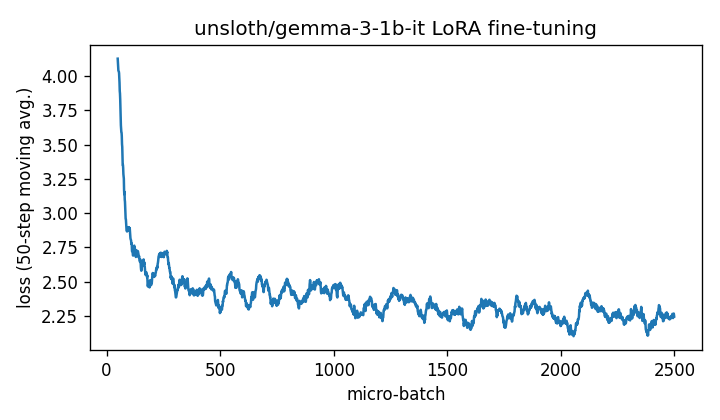

In [8]:
import matplotlib.pyplot as plt
OUT = f"results/{KEY}_lora"; os.makedirs(OUT, exist_ok=True)
pd.DataFrame(dict(micro_step=range(1, len(log) + 1), loss=log)).to_csv(f"{OUT}/history.csv", index=False)
plt.figure(figsize=(6, 3.5)); plt.plot(pd.Series(log).rolling(50).mean())
plt.xlabel("micro-batch"); plt.ylabel("loss (50-step moving avg.)"); plt.title(f"{MODEL_ID} LoRA fine-tuning")
plt.tight_layout(); plt.savefig(f"{OUT}/training_curve.png", dpi=120); plt.show()

## 3. Translating with the fine-tuned model (greedy and with temperature)

In [9]:
model = model.merge_and_unload()     # fold the adapters into the weights -> plain model, faster generation
stats = dict(model="Gemma-3-1B-IT (LoRA)", architecture="decoder-only", adaptation="LoRA fine-tuning (PEFT)",
             params=n_params, trainable_params=n_trainable, train_pairs=len(train_ex), train_time_s=train_time,
             epochs=1, val_loss_before=val_before, best_val_loss=val_after,
             tokenizer=stats_zs["tokenizer"], **token_stats)
stats.update(run_all(translate, "LoRA", OUT))
run_temperatures(lambda xs, T: translate(xs, temperature=T), OUT)
json.dump(stats, open(f"{OUT}/stats.json", "w"), indent=1)
stats

[LoRA] BLEU 14.11 | chrF 39.59 | 360.1s for 1000 sentences
  EN : Due to financial constraints Dhirubhai had to drop out after high school.
  REF: आर्थिक तंगी के कारण धीरूभाई को हाईस्कूल के बाद ही पढ़ाई छोड़ना पड़ गई।
  HYP: वित्तीय बाधाओं के कारण डीएचआरबीवी ने उच्च विद्यालय में पढ़ाई छोड़ दी।

  EN : Or they can choose not to have a device at all, opting instead to pay a flat fee based on the average number of miles driven by all state residents.
  REF: या फिर से कोई भी डिवाइस न लेना चुन सकते हैं, बल्कि राज्य के निवासियों द्वारा तय किए जाने वाले औसत मीलों के आधार पर निर्धारित शुल्क देना चुन सकते हैं।
  HYP: या वे किसी भी उपकरण का उपयोग नहीं कर सकते, बल्कि औसत रूप से सभी राज्यवासियों द्वारा चलाए गए मील की संख्या पर आधारित एक फ्लैट शुल्क का भुगतान कर सकते हैं।

  EN : However, following the recent murder of Australian travel agent Michelle Smith in Phuket, Thailand may also be looking to repair its battered tourist image, leading to an acquittal.
  REF: वैसे हाल ही में फुकेट में ऑस्ट्रे

{'model': 'Gemma-3-1B-IT (LoRA)',
 'architecture': 'decoder-only',
 'adaptation': 'LoRA fine-tuning (PEFT)',
 'params': 999885952,
 'trainable_params': 13045760,
 'train_pairs': 10000,
 'train_time_s': 1624.491365898,
 'epochs': 1,
 'val_loss_before': 4.242915917602658,
 'best_val_loss': 2.068329430245734,
 'tokenizer': 'GemmaTokenizer (262,145 tokens)',
 'avg_tokens_en': 25.602,
 'avg_tokens_hi': 32.079,
 'infer_time_s': 360.1193756849998,
 'infer_sent_per_s': 2.7768569744348066,
 'quick_bleu': 14.11052060843405,
 'quick_chrf': 39.586648240687}

In [10]:
import shutil; shutil.make_archive("results_gemma", "zip", ".", "results")   # download this file